In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as st
import pickle

import warnings

from tqdm.notebook import tqdm
from scipy.stats import beta
from scipy import stats
from scipy import integrate
from scipy import special
from concurrent.futures import ProcessPoolExecutor

In [2]:
#Simulation_itelation

rep_sim = 1000
rep_sim = 100000
rep_sim = 445000
rep_sim = 528400

In [3]:
# Difinition of Runge-Kutta methods

def rk4 ( y, t, h, f ):
    k1 = h * f( y, t )
    k2 = h * f( y + k1/2, t + h/2 )
    k3 = h * f( y + k2/2, t + h/2 )
    k4 = h * f( y + k3, t + h )
    return  y + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h

In [4]:
# Seed definitions

def SEEDS(seed):
    seeds = seed
    if seeds > 2**32 - 1:
        seeds = seeds/0.9 - 2**32
        if seeds > 2**32 - 1:
            seeds = seeds/0.9 - 2**32
            if seeds > 2**32 - 1:
                seeds = seeds/0.9 - 2**32
    np.random.seed(round(seeds))
    DecidedSeed = np.random.randint(0, 2**32)
    return DecidedSeed

In [5]:
# Difinition of PERT distribution

def PERT(a,b,c):
    return a+(c-a)*np.random.beta(1+4*(b-a)/(c-a), 1+4*(c-b)/(c-a))

In [6]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (Normal dist.)
#メトロポリスヘイスティング (正規分布)
def Metropolis_Hastings_norm(Temp_mean, sigma_Temp, Time_end, Temp0):
    Time_end = round(Time_end,1)
    def f(x):
        return stats.norm.pdf(x, Temp_mean, sigma_Temp)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    y = Temp0
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [7]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (PERT dist.)
#メトロポリスヘイスティング　（PERT分布）
def Metropolis_Hastings_pert(Temp_min, Temp_med, Temp_max, Time_end, Temp0):
    Time_end = round(Time_end,1)
    alpha = 1+4*(Temp_med-Temp_min)/(Temp_max-Temp_min)
    beta = 1+4*(Temp_max-Temp_med)/(Temp_max-Temp_min)

    def f(x):
        x_pert = (x - Temp_min)/(Temp_max-Temp_min)
        return stats.beta.pdf(x_pert, alpha, beta)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    
    if Temp0 > Temp_max:
        Temp0pert = Temp_max
    if Temp0 < Temp_min:
        Temp0pert = Temp_min
    else:
        Temp0pert = Temp0
    
    y = Temp0pert
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [8]:
def ROUND4(Value):
    if np.abs(Value) == float('inf'):
        RT = Value
    else:
        log = -np.log10(np.abs(Value))
        if log == float('inf'):
            RT = Value
        if log == -float('inf'):
            RT = Value
        else:
            if Value > 0:
                log = round(log)
                Tlog = log + 4
                RT = round(Value, Tlog)
            if Value < 0:
                log = round(log)
                Tlog = log + 4
                RT = round(Value, Tlog)
    return RT

In [9]:
def Mass_lettuce():  # This study
    return PERT(300, 480, 650)

In [10]:
def Prev_Init_Letuce(m_lettuce):
    # Prevalence (Franz, 2010)
    Pre_P = np.random.beta(1+1,2593-1+1)
    CheckLettuceContami = np.random.binomial(n = 1, p = Pre_P)
    
    # Initial Count (52 CFU/1000 g) (Franz et. al., 2010)
    logC_initial = np.log10(np.random.poisson(52*m_lettuce/1000)/m_lettuce)
    
    if CheckLettuceContami == 0:
        logC_initial = -float('inf')
    
    return Pre_P, CheckLettuceContami, logC_initial # (-), logcfu/g

In [11]:
def Prev_Init_Meat():
    ID_choice = 0
    if ID_choice == 0:
        # Prevalence (Carney, 2006)
        Pre_P = np.random.choice([0.024, 0.0322, 0.0122])
        CheckMeatContami = np.random.binomial(n = 1, p = Pre_P)

        # Initial Count (log CFU/g) (Carney, 2006)
        X = [0.7, 1.0, 1.5, 2.0, 2.5, 3]
        P = [0, 35, 60, 85, 96, 100]

        p = np.random.uniform(np.min(P), np.max(P))

        for i in range(len(P)):
            if not i==np.max(range(len(P))):
                if ((P[i]<= p)&(p<P[i+1])):
                    logC_initial = np.random.uniform(X[i], X[i+1])
        if CheckMeatContami == 0:
            logC_initial = -float('inf')
    
    
    if ID_choice == 1:
        # This study????
        Pre_P = np.random.beta(75.7+1,100-75.7+1)
        CheckMeatContami = np.random.binomial(n = 1, p = Pre_P)

        # This study???? (log CFU/g) (Carney, 2006)
        C_initial = np.random.uniform(0, 10**6)
        logC_initial = np.log10(C_initial)
        if CheckMeatContami == 0:
            logC_initial = -float('inf')
    
    
    return Pre_P, CheckMeatContami, logC_initial # (-), logcfu/g

In [12]:
# Time_temp history is observed by Koseki&Isobe (2005)
Time_temp_trans_reference = pd.read_csv("data/transportation/Temperature_histroy_1.csv")

In [13]:
Temp_ref_trans = Time_temp_trans_reference["Temp_cool"]
Temp_ref_min_trans = np.min(Temp_ref_trans)
Temp_ref_med_trans = np.median(Temp_ref_trans)
Temp_ref_max_trans = np.max(Temp_ref_trans)

In [14]:
print(Temp_ref_min_trans)
print(Temp_ref_med_trans)
print(Temp_ref_max_trans)

1.5
6.5
16.7


In [15]:
def Temp_trans(Time_end):
    Temp0 = PERT(Temp_ref_min_trans, Temp_ref_med_trans, Temp_ref_max_trans)
    return Metropolis_Hastings_pert(Temp_ref_min_trans, Temp_ref_med_trans, Temp_ref_max_trans, Time_end, Temp0)#Koseki et al., 2005

In [16]:
def Time_trans():
    return np.random.uniform(30, 63) #Koseki et al., 2005

In [17]:
def Temp_home(Time_end, Temp0):
    return Metropolis_Hastings_norm(3.45, 2.44, Time_end, Temp0) # Pang et al., 2017

In [18]:
def Time_home():
    return  PERT(12, 48, 168) #Storage at home (Ding et al., 2013)

In [19]:
sm_growth_Ecoli = pickle.load(open('stan_model_growth_Ecoli.pkl', 'rb'))
fit_growth_Ecoli = pickle.load(open('fit_nuts_Ecoli_growth.pkl', 'rb'))
samples_growth_Ecoli = fit_growth_Ecoli.extract(permuted=True)
fit_growth_Ecoli_meat = pickle.load(open('fit_nuts_Ecoli_growth_beef.pkl', 'rb'))
samples_growth_Ecoli_meat = fit_growth_Ecoli_meat.extract(permuted=True)

def Growth_paras():
    rcn_Ecoli = np.random.choice(range(len(samples_growth_Ecoli["lp__"])))
    a  = samples_growth_Ecoli["a"][rcn_Ecoli]
    b  = samples_growth_Ecoli["b"][rcn_Ecoli]
    c  = samples_growth_Ecoli["c"][rcn_Ecoli]
    d  = samples_growth_Ecoli["d"][rcn_Ecoli]
    h0 = samples_growth_Ecoli["h0"][rcn_Ecoli]
    return a, b, c, d, h0

def Growth_meat_paras():
    rcn_Ecoli = np.random.choice(range(len(samples_growth_Ecoli_meat["lp__"])))
    a  = samples_growth_Ecoli_meat["a"][rcn_Ecoli]
    b  = samples_growth_Ecoli_meat["b"][rcn_Ecoli]
    c  = samples_growth_Ecoli_meat["c"][rcn_Ecoli]
    d  = samples_growth_Ecoli_meat["d"][rcn_Ecoli]
    h0 = samples_growth_Ecoli_meat["h0"][rcn_Ecoli]
    return a, b, c, d, h0



In [20]:
def rk4_Baranyi_dqdt(q, t, h, mu_max):
    def f (q, t):
        return mu_max * q
    k1 = h * f( q, t )
    k2 = h * f( q + k1/2, t + h/2 )
    k3 = h * f( q + k2/2, t + h/2 )
    k4 = h * f( q + k3, t + h )
    return  q + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
def rk4_Baranyi_dCdt(C, t, h, mu_max, q, Cmax):
    def f (C, t):
        return mu_max * q / (1+q) * (1 - C/Cmax) * C
    k1 = h * f( C, t )
    k2 = h * f( C + k1/2, t + h/2 )
    k3 = h * f( C + k2/2, t + h/2 )
    k4 = h * f( C + k3, t + h )
    return  C + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
    
def Differential_Baranyi_dqdt(q, mu_max):  ### q description
    return mu_max * q
    
def Differential_Baranyi_dCdt(C, mu_max, q, Cmax):  ### Natural log
    return mu_max * q / (1+q) * (1 - C/Cmax) * C


In [21]:
def Cross_probs():
    CheckLettuceAfterMeat = np.random.binomial(1, 0.366)
    X_meat2uten  = CheckLettuceAfterMeat * np.random.beta(0.33+1, 0.53) # ??? Dharod et al., 2009???
    X_meat2hand  = CheckLettuceAfterMeat * np.min([np.random.lognormal(0.94, 0.68)/100, 1])
    X_uten2hand  = CheckLettuceAfterMeat * np.random.beta(0.33+1, 0.53)
    CheckHandWash = np.random.binomial(1, 0.748)
    if CheckHandWash == 1:
        X_reduc_wash  = CheckLettuceAfterMeat*np.min([np.random.lognormal(-0.20, 1.42)/100, 1])
    if CheckHandWash == 0:
        X_reduc_wash  = CheckLettuceAfterMeat*1
    X_hand2lettuce = CheckLettuceAfterMeat * np.min([np.random.lognormal(-0.80, 1.09)/100, 1])
    
    return X_meat2uten, X_meat2hand, X_uten2hand, X_reduc_wash, X_hand2lettuce, CheckHandWash, CheckLettuceAfterMeat

In [ ]:
def Cross_probs():
    CheckLettuceAfterMeat = np.random.binomial(1, 0.366)
    X_meat2uten  = CheckLettuceAfterMeat * np.random.beta(2.1, 9.79)
    X_meat2hand  = CheckLettuceAfterMeat *np.random.beta(0.57, 4.29)
    X_uten2hand  = CheckLettuceAfterMeat * np.random.beta(0.29, 3.82)
    CheckHandWash = np.random.binomial(1, 0.748)
    if CheckHandWash == 1:
        X_reduc_wash  = CheckLettuceAfterMeat*np.random.beta(0.25, 7.4)
    if CheckHandWash == 0:
        X_reduc_wash  = CheckLettuceAfterMeat*1
    X_hand2lettuce = CheckLettuceAfterMeat * np.random.beta(0.4, 21.65)
    
    return X_meat2uten, X_meat2hand, X_uten2hand, X_reduc_wash, X_hand2lettuce, CheckHandWash, CheckLettuceAfterMeat

In [22]:
def lettuceWash():
    CheckLettuceWash = np.random.binomial(1, 1-0.366)
    reduc_lettuce_wash = PERT(10**(3.5-5.4), 10**(4.2-5.0), 1)**(CheckLettuceWash)#Uhlig et al.,2017
    return CheckLettuceWash, reduc_lettuce_wash

In [23]:
def DRmodel_Appro_Beta_Pois(Dose):
    alpha_BetaPois = 0.2241 #Strachan et al., 2005
    beta_BetaPois = 4.8807 #Strachan et al., 2005
    P_DR = 1.0 - (1+Dose/beta_BetaPois)**-alpha_BetaPois #Approximate Beta-Poisson DR model
    return P_DR

In [24]:
def ServeSize(m_lettuce):
    servesize = m_lettuce/round(m_lettuce/85) # 85g of mean size FDA???
    return servesize # g

In [25]:
def PackSize_Meat():
    return PERT(150, 200, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)
def ServeSize_Meat():
    return PERT(50, 85, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)

In [26]:
def determineInfection(P_inf):
    return np.random.binomial(1, P_inf)

In [27]:
def QMRA_calculations(ID_sim):
    ### Setting of the seed for the random numbers
    np.random.seed(SEEDS(19990128+ID_sim))
    
    ### Weight of lettuce
    m_lettuce = Mass_lettuce()
    m_meat = PackSize_Meat()
    
    ### Prevalence and Initial conc.
    p_lettuce, checklettuce0, logC0_lettuce = Prev_Init_Letuce(m_lettuce) # Lettuce
    p_meat, checkmeat0, logC0_meat  = Prev_Init_Meat() # meat
    
    ### Initial count in lettuce
    N0 = m_lettuce * 10**logC0_lettuce # CFU
    N0 = np.random.poisson(N0) # CFU
    logN0 = np.log10(N0) # logCFU
    logC0_lettuce = np.log10(N0/m_lettuce) # logCFU/g
    
    ### Initial count in meat
    N0_meat = m_meat * 10**logC0_meat # CFU
    N0_meat = np.random.poisson(N0_meat) # CFU
    logN0_meat = np.log10(N0_meat) # logCFU
    logC0_meat = np.log10(N0_meat/m_meat) # logCFU/g
    
    ### Growth parameters
    a_growth, b_growth, c_growth, d_growth, h0_growth = Growth_paras()
    q0_growth = 1/(np.exp(h0_growth)-1)
    
    a_growth_meat, b_growth_meat, c_growth_meat, d_growth_meat, h0_growth_meat = Growth_meat_paras()
    q0_growth_meat = 1/(np.exp(h0_growth_meat)-1)
    
    ### Time and Temp. during transportation
    time_trans = Time_trans()
    ts_trans, temp_trans = Temp_trans(time_trans)
    
    ### Estimation of growth during transportation
    logCs_trans = np.empty(len(ts_trans))
    for i in range(len(ts_trans)):
        if i ==0:
            q = q0_growth
            logC_lettuce = logC0_lettuce
            logCs_trans[i] = logC_lettuce
        else:
            time = ts_trans[i]
            temp = np.mean([temp_trans[i],temp_trans[i-1]])
            if (temp-d_growth) > 0:
                mu_max = (c_growth * (temp-d_growth))**2
            else:
                mu_max = 0
            Cmax = np.exp(a_growth * temp + b_growth)
            
            C_lettuce = 10**logC_lettuce
            
            if C_lettuce > Cmax:
                logCs_trans[i] = logC_lettuce
            else:
                q = rk4_Baranyi_dqdt(q, time, 0.1, mu_max)[0]
                C_lettuce = rk4_Baranyi_dCdt(C_lettuce, time, 0.1, mu_max, q, Cmax)[0]
                logC_lettuce = np.log10(C_lettuce)
                logCs_trans[i] = logC_lettuce
    
    logC_trans = logC_lettuce
    if not N0 ==0:
        N_trans = N0 + np.random.negative_binomial(N0, 10**(logC0_lettuce-logC_trans))
    else:
        N_trans = N0
    logN_trans = np.log10(N_trans)
    logC_trans = np.log10(N_trans/m_lettuce)
    
    ### Time and Temp. during home storage
    time_home = Time_home()
    ts_home, temp_home = Temp_home(time_home, temp_trans[-1])
    
    ### Estimation of growth during home storage
    logCs_home = np.empty(len(ts_home))
    for i in range(len(ts_home)):
        if i ==0:
            q = q
            logC_lettuce = logC_trans
            logCs_home[i] = logC_lettuce
        else:
            time = ts_home[i]
            temp = np.mean([temp_home[i],temp_home[i-1]])
            if (temp-d_growth) > 0:
                mu_max = (c_growth * (temp-d_growth))**2
            else:
                mu_max = 0
            Cmax = np.exp(a_growth * temp + b_growth)
            
            C_lettuce = 10**logC_lettuce
            
            if C_lettuce > Cmax:
                logCs_home[i] = logC_lettuce
            else:
                q = rk4_Baranyi_dqdt(q, time, 0.1, mu_max)[0]
                C_lettuce = rk4_Baranyi_dCdt(C_lettuce, time, 0.1, mu_max, q, Cmax)[0]
                logC_lettuce = np.log10(C_lettuce)
                logCs_home[i] = logC_lettuce
    
    logC_home = logC_lettuce
    if not N_trans == 0:
        N_home_lettuce = N_trans + np.random.negative_binomial(N_trans, 10**(logC_trans-logC_home))
    else:
        N_home_lettuce = N_trans
    logN_home = np.log10(N_home_lettuce)
    logC_home = np.log10(N_home_lettuce/m_lettuce)
    
    
    
    
    
    ### Time and Temp. during trans_meatportation
    time_trans_meat = Time_trans()
    ts_trans_meat, temp_trans_meat = Temp_trans(time_trans_meat)
    
    ### Estimation of growth_meat during transportation
    logCs_trans_meat = np.empty(len(ts_trans_meat))
    for i in range(len(ts_trans_meat)):
        if i ==0:
            q_meat = q0_growth_meat
            logC_meat = logC0_meat
            logCs_trans_meat[i] = logC_meat
        else:
            time = ts_trans_meat[i]
            temp = np.mean([temp_trans_meat[i],temp_trans_meat[i-1]])
            if (temp-d_growth_meat) > 0:
                mu_max_meat = (c_growth_meat * (temp-d_growth_meat))**2
            else:
                mu_max_meat = 0
            Cmax_meat = np.exp(a_growth_meat * temp + b_growth_meat)
            
            C_meat = 10**logC_meat
            
            if C_meat > Cmax_meat:
                logCs_trans_meat[i] = logC_meat
            else:
                q_meat = rk4_Baranyi_dqdt(q_meat, time, 0.1, mu_max_meat)[0]
                C_meat = rk4_Baranyi_dCdt(C_meat, time, 0.1, mu_max_meat, q_meat, Cmax_meat)[0]
                logC_meat = np.log10(C_meat)
                logCs_trans_meat[i] = logC_meat
    
    logC_trans_meat = logC_meat
    if not N0_meat ==0:
        N_trans_meat = N0_meat + np.random.negative_binomial(N0_meat, 10**(logC0_meat-logC_trans_meat))
    else:
        N_trans_meat = N0_meat
    logN_trans_meat = np.log10(N_trans_meat)
    logC_trans_meat = np.log10(N_trans_meat/m_meat)
    
    ### Time and Temp. during home_meat storage
    time_home_meat = Time_home()
    ts_home_meat, temp_home_meat = Temp_home(time_home_meat, temp_trans_meat[-1])
    
    ### Estimation of growth_meat during home_meat storage
    logCs_home_meat = np.empty(len(ts_home_meat))
    for i in range(len(ts_home_meat)):
        if i ==0:
            q_meat = q_meat
            logC_meat = logC_trans_meat
            logCs_home_meat[i] = logC_meat
        else:
            time = ts_home_meat[i]
            temp = np.mean([temp_home_meat[i],temp_home_meat[i-1]])
            if (temp-d_growth_meat) > 0:
                mu_max_meat = (c_growth_meat * (temp-d_growth_meat))**2
            else:
                mu_max_meat = 0
            Cmax_meat = np.exp(a_growth_meat * temp + b_growth_meat)
            
            C_meat = 10**logC_meat
            
            if C_meat > Cmax_meat:
                logCs_home_meat[i] = logC_meat
            else:
                q_meat = rk4_Baranyi_dqdt(q_meat, time, 0.1, mu_max_meat)[0]
                C_meat = rk4_Baranyi_dCdt(C_meat, time, 0.1, mu_max_meat, q_meat, Cmax_meat)[0]
                logC_meat = np.log10(C_meat)
                logCs_home_meat[i] = logC_meat
    
    logC_home_meat = logC_meat
    if not N_trans_meat == 0:
        N_home_meat = N_trans_meat + np.random.negative_binomial(N_trans_meat, 10**(logC_trans_meat-logC_home_meat))
    else:
        N_home_meat = N_trans_meat
    logN_home_meat = np.log10(N_home_meat)
    logC_home_meat = np.log10(N_home_meat/m_meat)
    
    
    
    
    ### Cross contaminations
    size_meat = np.min([ServeSize_Meat(), m_meat]) # g
    
    x_meat2uten, x_meat2hand, x_uten2hand, x_reduc_wash, x_hand2lettuce, checkhandwash, checklettuceaftermeat = Cross_probs()
    
    contami_meat = np.random.binomial(N_home_meat, size_meat/m_meat) #CFU/meat serve
    
    xcontami_meat2uten = np.random.binomial(contami_meat, x_meat2uten) #CFU
    xcontami_uten2hand = np.random.binomial(xcontami_meat2uten, x_uten2hand) #CFU
    xcontami_meat2hand = np.random.binomial(contami_meat, x_meat2hand) #CFU
    xcontami_hand = xcontami_uten2hand + xcontami_meat2hand #CFU
    xcontami_washed_hand = np.random.binomial(xcontami_hand, x_reduc_wash) #CFU
    xcontami_hand2lettuce = np.random.binomial(xcontami_washed_hand, x_hand2lettuce) #CFU
    
    ### Consumption
    size_serve = ServeSize(m_lettuce)
    
    contami_lettuce = np.random.binomial(N_home_lettuce, size_serve/m_lettuce)
    contami_lettuce_before_wash = contami_lettuce + xcontami_hand2lettuce
    
    ### Lettuce wash
    checklettucewash, reduc_lettuce_wash = lettuceWash()
    finalcontami_lettuce = np.random.binomial(contami_lettuce_before_wash, reduc_lettuce_wash) #CFU
    
    dose = finalcontami_lettuce
    logdose = np.log10(dose)
    
    ### Infection or not
    p_DR = DRmodel_Appro_Beta_Pois(dose)
    p_inf = p_DR
    checkInf = determineInfection(p_inf)
    
    ### Output selection
    output = pd.DataFrame({
        "checkInf": [checkInf],
        "m_lettuce": [round(m_lettuce,2)],
        "m_meat": [round(m_meat,2)],
        "p_lettuce": [round(p_lettuce,6)],
        "checklettuce0": [checklettuce0],
        "logC0_lettuce": [round(logC0_lettuce,2)],
        "p_meat": [round(p_meat,6)],
        "checkmeat0": [checkmeat0],
        "logC0_meat": [round(logC0_meat,2)],
        "a_growth_lettuce": [round(a_growth,6)],
        "b_growth_lettuce": [round(b_growth,2)],
        "c_growth_lettuce": [round(c_growth,6)],
        "d_growth_lettuce": [round(d_growth,2)],
        "h0_growth_lettuce": [round(h0_growth,2)],
        "q0_growth_lettuce": [round(q0_growth,2)],
        "a_growth_meat": [round(a_growth_meat,6)],
        "b_growth_meat": [round(b_growth_meat,2)],
        "c_growth_meat": [round(c_growth_meat,6)],
        "d_growth_meat": [round(d_growth_meat,2)],
        "h0_growth_meat": [round(h0_growth_meat,2)],
        "q0_growth_meat": [round(q0_growth_meat,2)],
        "time_trans_lettuce": [round(time_trans,2)],
        "ts_trans_lettuce": [np.round(ts_trans,2)],
        "temp_trans_lettuce": [np.round(temp_trans,2)],
        "temp_trans_mean_lettuce": [np.round(np.mean(temp_trans),2)],
        "logCs_trans_lettuce": [np.round(logCs_trans,2)],
        "logC_trans_lettuce": [round(logC_trans,2)],
        "time_home_lettuce": [round(time_home,2)],
        "ts_home_lettuce": [np.round(ts_home,2)],
        "temp_home_lettuce": [np.round(temp_home,2)],
        "temp_home_mean_lettuce": [np.round(np.mean(temp_home),2)],
        "logCs_home_lettuce": [np.round(logCs_home,2)],
        "logC_home_lettuce": [round(logC_home,2)],
        "time_trans_meat": [round(time_trans_meat,2)],
        "ts_trans_meat": [np.round(ts_trans_meat,2)],
        "temp_trans_meat": [np.round(temp_trans_meat,2)],
        "temp_trans_mean_meat": [np.round(np.mean(temp_trans_meat),2)],
        "logCs_trans_meat": [np.round(logCs_trans_meat,2)],
        "logC_trans_meat": [round(logC_trans_meat,2)],
        "time_home_meat": [round(time_home_meat,2)],
        "ts_home_meat": [np.round(ts_home_meat,2)],
        "temp_home_meat": [np.round(temp_home_meat,2)],
        "temp_home_mean_meat": [np.round(np.mean(temp_home_meat),2)],
        "logCs_home_meat": [np.round(logCs_home_meat,2)],
        "logC_home_meat": [round(logC_home_meat,2)],
        "size_meat": [round(size_meat,2)],
        "checklettuceaftermeat": [checklettuceaftermeat],
        "x_meat2uten": [round(x_meat2uten,6)],
        "x_meat2hand": [round(x_meat2hand,6)],
        "x_uten2hand": [round(x_uten2hand,6)],
        "x_reduc_wash": [round(x_reduc_wash,6)],
        "checkhandwash": [checkhandwash],
        "x_hand2lettuce": [round(x_hand2lettuce,6)],
        "contami_meat": [contami_meat],
        "xcontami_meat2uten": [xcontami_meat2uten],
        "xcontami_uten2hand": [xcontami_uten2hand],
        "xcontami_meat2hand": [xcontami_meat2hand],
        "xcontami_hand": [xcontami_hand],
        "xcontami_washed_hand": [xcontami_washed_hand],
        "xcontami_hand2lettuce": [xcontami_hand2lettuce],
        "contami_lettuce": [contami_lettuce],
        "size_serve": [round(size_serve,2)],
        "checklettucewash": [checklettucewash],
        "reduc_lettuce_wash": [round(reduc_lettuce_wash,6)],
        "logdose": [round(logdose,2)],
        "p_inf": [round(p_inf,4)]
    })
    return output

In [28]:
warnings.simplefilter('ignore', RuntimeWarning)
Sim_results =[]
ns = range(rep_sim)
with ProcessPoolExecutor(8) as e:
    ret = e.map(QMRA_calculations, ns)
Sim_results = [r for r in ret]
Sim_results = pd.concat(Sim_results)
Sim_results = Sim_results.reset_index()
Sim_results = Sim_results.drop(columns='index')

In [33]:
import datetime
with open('results/Simulation results of repsim.pkl', 'wb') as g:
    pickle.dump(Sim_results, g)

In [34]:
#Sim_results = pickle.load(open('results/Simulation results of repsim.pkl', 'rb'))

In [35]:
Sim_results

,checkInf,m_lettuce,m_meat,p_lettuce,checklettuce0,logC0_lettuce,p_meat,checkmeat0,logC0_meat,a_growth_lettuce,...,xcontami_meat2hand,xcontami_hand,xcontami_washed_hand,xcontami_hand2lettuce,contami_lettuce,size_serve,checklettucewash,reduc_lettuce_wash,logdose,p_inf
0,0,464.22,185.60,0.000762,0,-inf,0.0122,0,-inf,0.124696,...,0,0,0,0,0,92.84,0,1.000000,-inf,0.0
1,0,452.40,178.70,0.000387,0,-inf,0.0322,0,-inf,0.096245,...,0,0,0,0,0,90.48,0,1.000000,-inf,0.0
2,0,443.26,191.01,0.000225,0,-inf,0.0322,0,-inf,0.164938,...,0,0,0,0,0,88.65,1,0.472557,-inf,0.0
3,0,467.96,195.51,0.000967,0,-inf,0.0322,0,-inf,0.171146,...,0,0,0,0,0,77.99,1,0.128162,-inf,0.0
4,0,427.90,211.50,0.000855,0,-inf,0.0240,0,-inf,0.143741,...,0,0,0,0,0,85.58,0,1.000000,-inf,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528395,0,483.03,210.17,0.001345,0,-inf,0.0322,0,-inf,0.116930,...,0,0,0,0,0,80.50,1,0.199658,-inf,0.0
528396,0,568.14,169.88,0.000559,0,-inf,0.0122,0,-inf,0.157599,...,0,0,0,0,0,81.16,1,0.309353,-inf,0.0
528397,0,533.18,171.73,0.001815,0,-inf,0.0322,0,-inf,0.150044,...,0,0,0,0,0,88.86,1,0.377968,-inf,0.0
528398,0,456.34,166.67,0.000804,0,-inf,0.0322,0,-inf,0.121647,...,0,0,0,0,0,91.27,1,0.066861,-inf,0.0


In [36]:
Sensitivity_corr = Sim_results.corr(method="spearman")
Sensitivity_corr["checkInf"].to_csv("results/Illness occurrence Spearman.csv")
Sensitivity_corr["logdose"].to_csv("results/log dose Spearman.csv")
Sensitivity_corr = Sensitivity_corr.reindex(Sensitivity_corr["checkInf"].abs().sort_values().index)

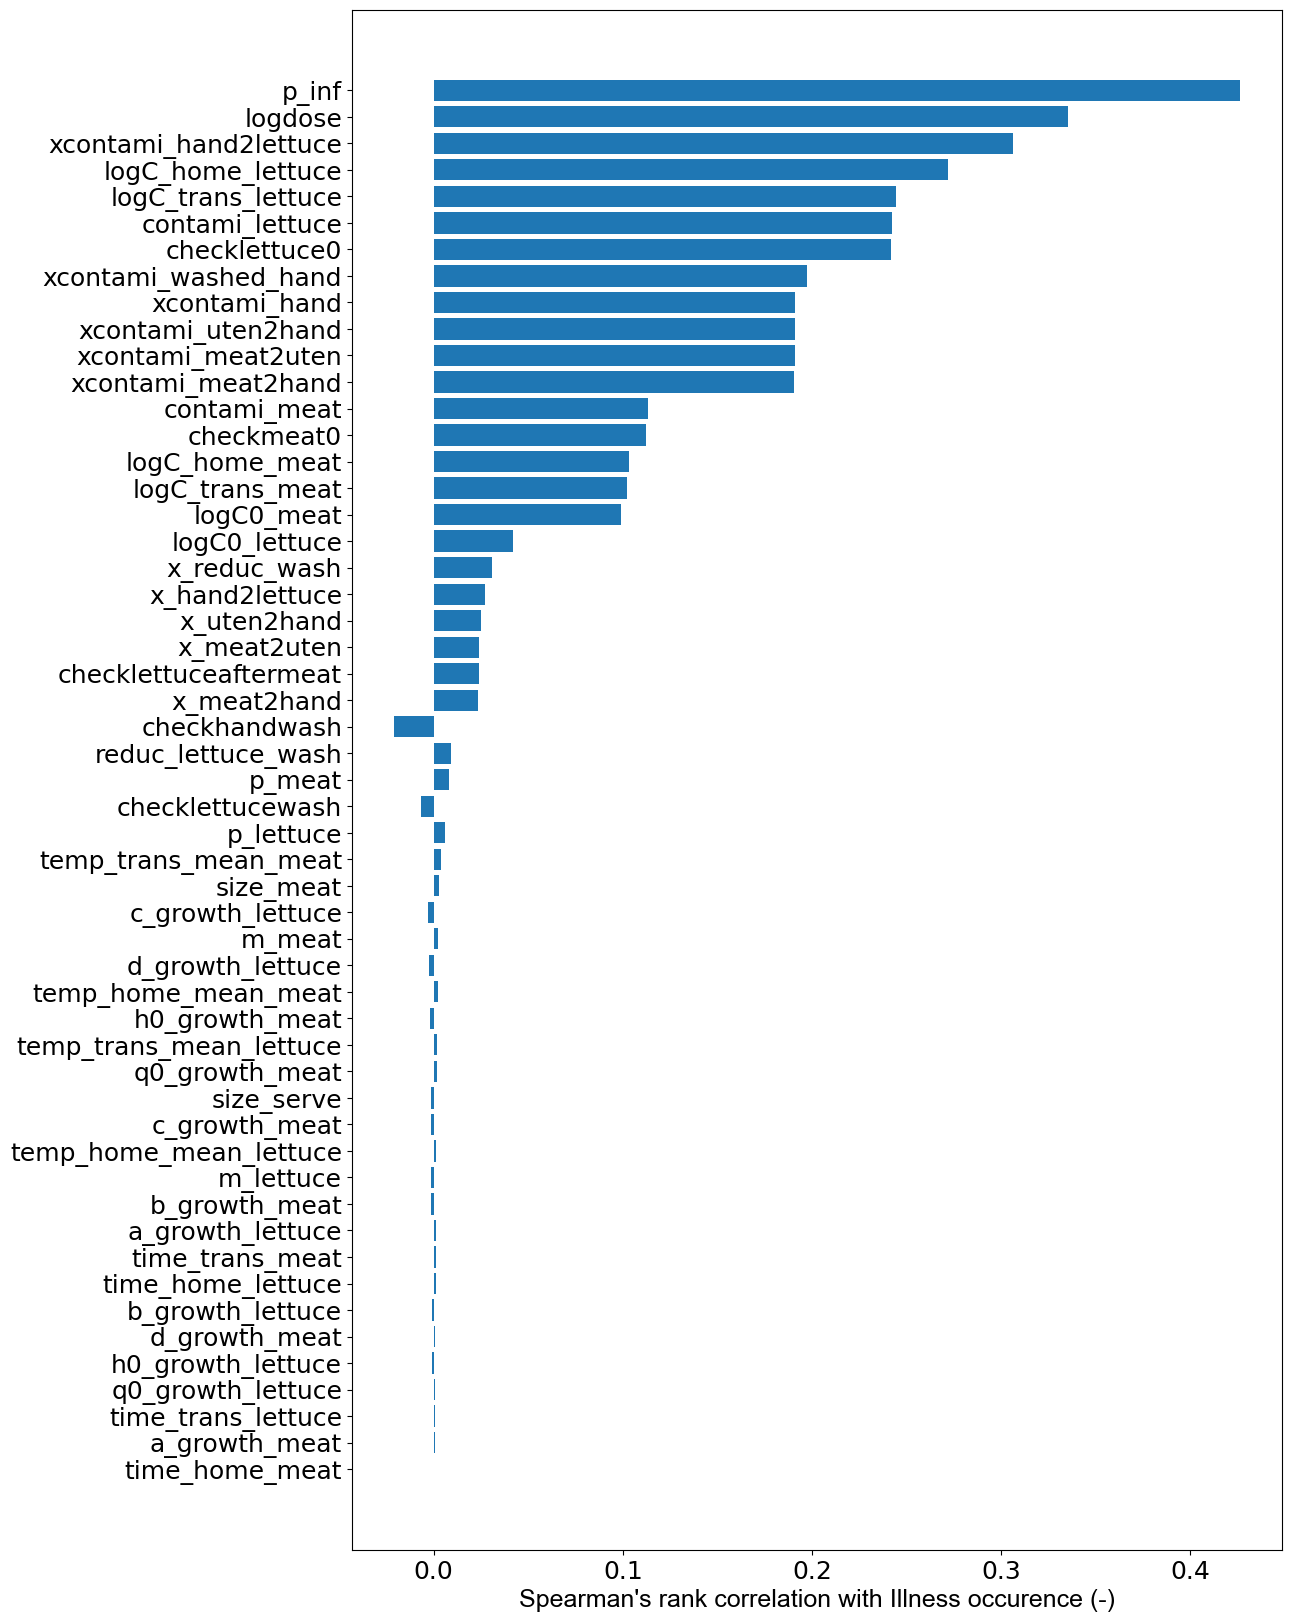

In [37]:
fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_corr.index[0:len(Sensitivity_corr["checkInf"])-1], 
        Sensitivity_corr["checkInf"][0:len(Sensitivity_corr["checkInf"])-1])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with Illness occurence (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman.pdf", bbox_inches="tight", dpi=500)
plt.show()

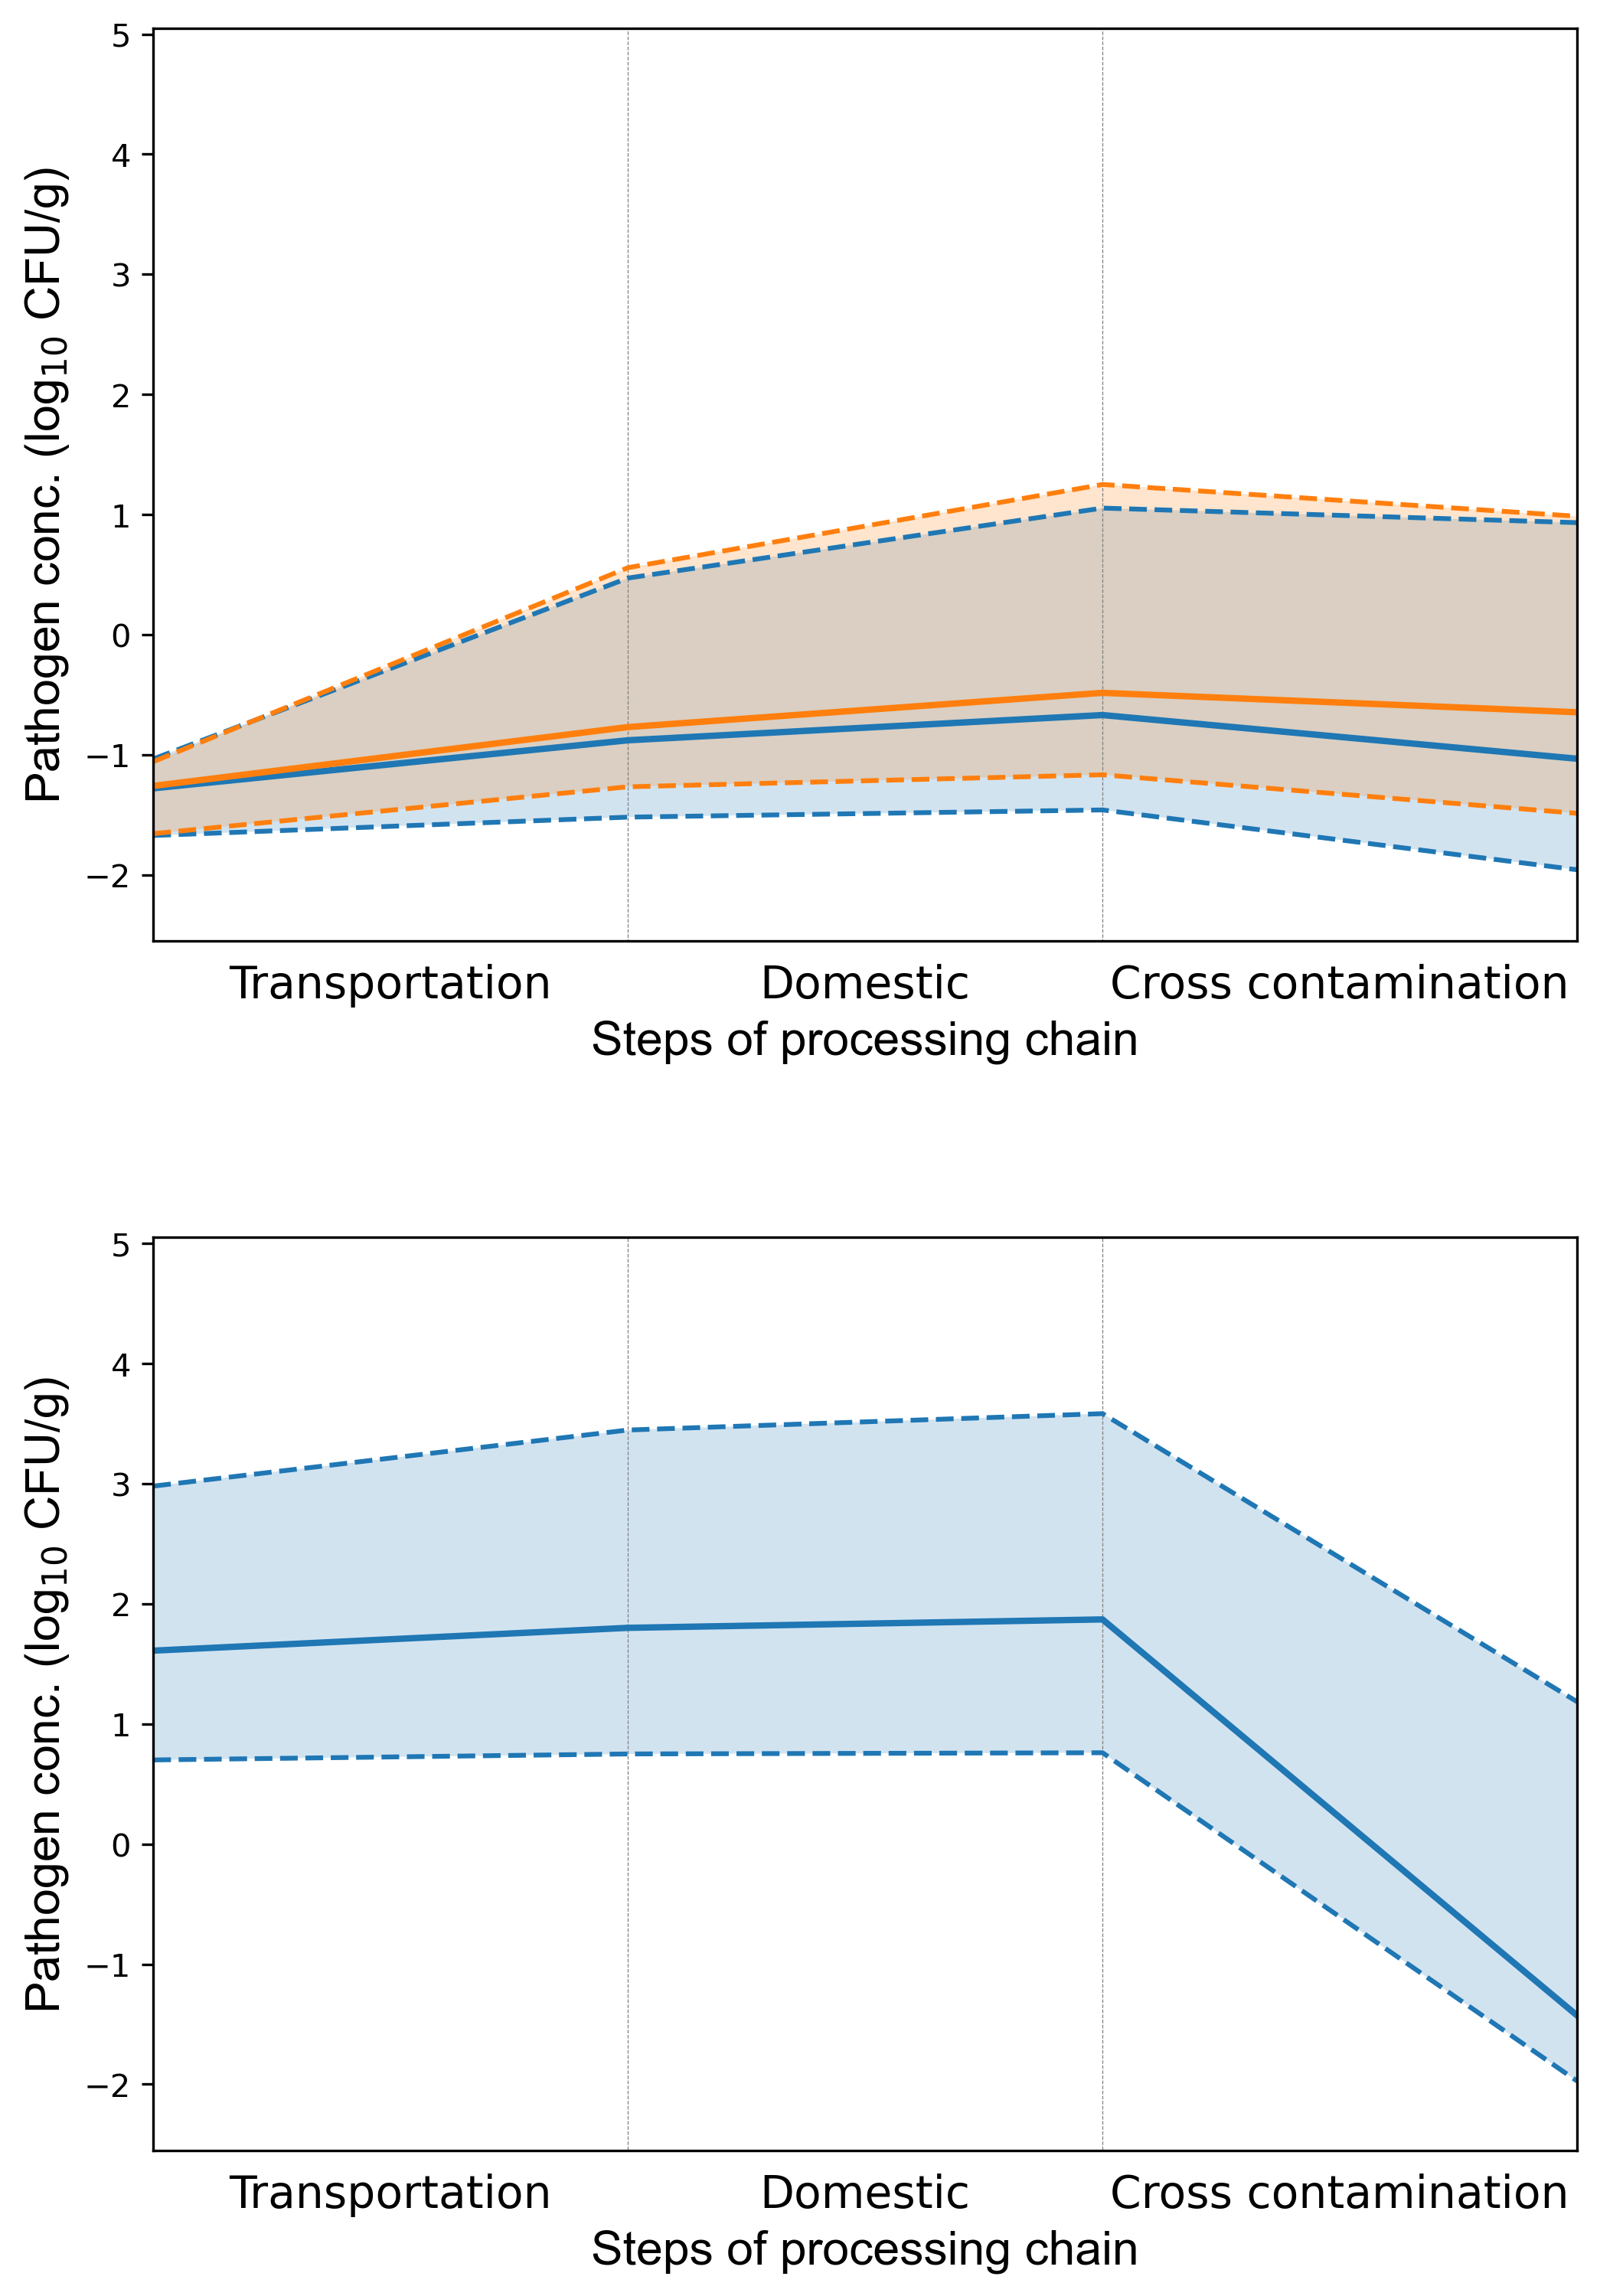

In [38]:
Palette=sns.color_palette(n_colors = 4)
logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC0_lettuce"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_trans_lettuce"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_home_lettuce"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["size_serve"])


logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))



fig, ax = plt.subplots(2, 1, gridspec_kw={'width_ratios': [1], 'height_ratios': [1, 1]},figsize=(8,12), dpi=300)
plt.subplots_adjust(wspace=0, hspace=0.325)
plt.rcParams["font.family"] = "Arial"


ax[0].set_xticks([0.5, 1.5, 2.5])
ax[0].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[0].tick_params(bottom=False)
ax[0].set_ylim([-2.55, 5.05])
ax[0].set_xlim([-0, 3])



ax[0].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[0].set_ylabel("Pathogen conc. (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[0].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[0].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)
ax[0].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)

#ax[0].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)

#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)].index:
#        ax[0].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)


ax[0].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')


ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')



logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC0_meat"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_trans_meat"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_home_meat"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["size_serve"])

if len(logC0_ill) < 3:
    logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
    logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
    logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
    logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))

ax[1].set_xticks([0.5, 1.5, 2.5])
ax[1].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[1].tick_params(bottom=False)
ax[1].set_ylim([-2.55, 5.05])
ax[1].set_xlim([-0, 3])



ax[1].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[1].set_ylabel("Pathogen conc. (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[1].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[1].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)

if len(logC0_ill) < 3:
    ax[1].fill_between([0,1,2,3], 
                       [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                       alpha=0.2)

#ax[1].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)


#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)].index:
#        ax[1].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)

ax[1].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[1].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[1].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')



if len(logC0_ill) < 3:
    ax[1].plot([0,1,2,3], 
               [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
    ax[1].plot([0,1,2,3], 
               [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
    ax[1].plot([0,1,2,3], 
               [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')


plt.savefig("plot/Step and conc.pdf", bbox_inches="tight", dpi=500)
plt.show()

In [39]:
ax[1].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)


In [40]:
np.sum(Sim_results["checkInf"])

308

In [41]:
Sim_results["logC_home_lettuce"][Sim_results["checklettuce0"]==1]

854      -0.95
2360     -0.39
2969     -0.73
3349     -0.49
3376     -0.73
          ... 
523906    0.34
524047   -0.18
524103   -0.98
524600   -0.60
528073   -0.54
Name: logC_home_lettuce, Length: 409, dtype: float64

In [42]:
Sim_results["logC_home_meat"][Sim_results["checkmeat0"]==1]

12        0.98
19        2.51
66        2.03
205       0.89
253       1.22
          ... 
528319    2.14
528335    1.67
528337    2.55
528354    1.03
528393    3.64
Name: logC_home_meat, Length: 12200, dtype: float64

In [43]:
Sim_results["logdose"][Sim_results["logdose"]!=-np.inf]

19        1.60
253       0.90
433       0.00
854       0.30
1652      0.30
          ... 
527058    0.00
527368    0.00
528073    1.36
528095    0.95
528319    0.30
Name: logdose, Length: 1696, dtype: float64

In [44]:
np.sum(Sim_results ["checkmeat0"])

12200

In [45]:
np.sum(Sim_results["checkInf"])

308

In [46]:
Sim_results[Sim_results["checkInf"]==1]["checkmeat0"]

1861      1
3376      0
3463      0
3477      1
3954      1
         ..
520542    1
522987    1
524117    1
525623    1
526449    1
Name: checkmeat0, Length: 308, dtype: int64

In [47]:
Sim_results[Sim_results["checkInf"]==1]["checklettuce0"]

1861      0
3376      1
3463      1
3477      0
3954      0
         ..
520542    0
522987    0
524117    0
525623    0
526449    0
Name: checklettuce0, Length: 308, dtype: int64

In [48]:
Sim_results[Sim_results["checkInf"]==1]["checkhandwash"]

1861      0
3376      0
3463      1
3477      1
3954      0
         ..
520542    0
522987    1
524117    1
525623    0
526449    1
Name: checkhandwash, Length: 308, dtype: int64

In [49]:

Testtemp_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_lettuce"]!=-np.inf)].reset_index()["temp_trans_lettuce"]
TestlogC_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_lettuce"]!=-np.inf)].reset_index()["logCs_trans_lettuce"]
Testts_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_lettuce"]!=-np.inf)].reset_index()["ts_trans_lettuce"]
Testts = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)].reset_index()["ts_trans_meat"]
Testtemp = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)].reset_index()["temp_trans_meat"]
TestlogC = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)].reset_index()["logCs_trans_meat"]


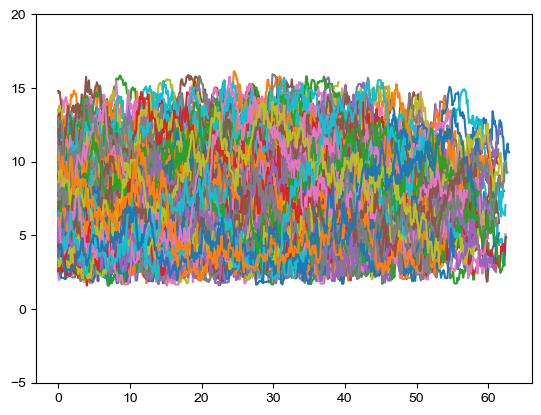

In [50]:
for i in Testts.index:
    plt.plot(Testts[i], Testtemp[i])
plt.ylim([-5.05, 20.05])
plt.show()

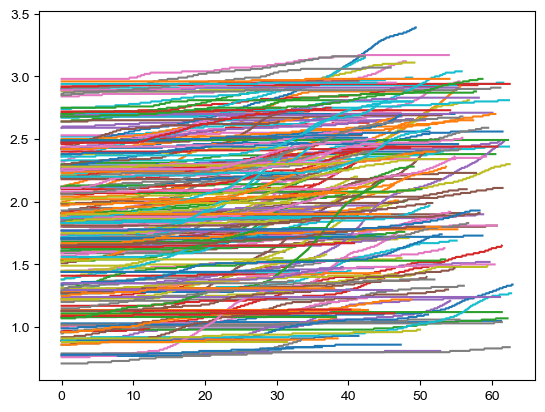

In [51]:
for i in Testts.index:
    plt.plot(Testts[i], TestlogC[i])
plt.show()

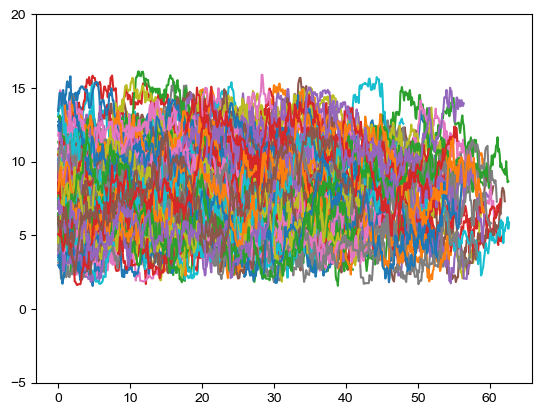

In [52]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], Testtemp_lettuce[i])
plt.ylim([-5.05, 20.05])
plt.show()

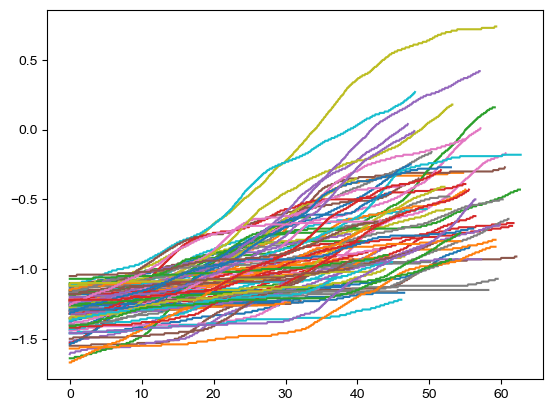

In [53]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], TestlogC_lettuce[i])
plt.show()

In [54]:

Testtemp_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_lettuce"]!=-np.inf)].reset_index()["temp_home_lettuce"]
TestlogC_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_lettuce"]!=-np.inf)].reset_index()["logCs_home_lettuce"]
Testts_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_lettuce"]!=-np.inf)].reset_index()["ts_home_lettuce"]
Testts = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)].reset_index()["ts_home_meat"]
Testtemp = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)].reset_index()["temp_home_meat"]
TestlogC = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)].reset_index()["logCs_home_meat"]


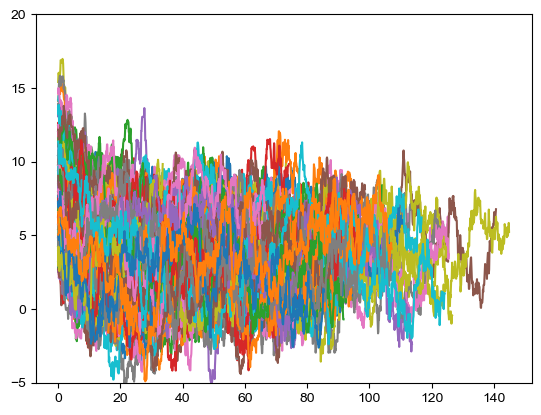

In [55]:
for i in Testts.index:
    plt.plot(Testts[i], Testtemp[i])
plt.ylim([-5.05, 20.05])
plt.show()

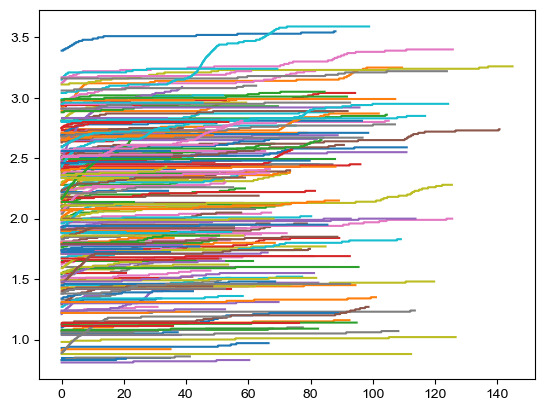

In [56]:
for i in Testts.index:
    plt.plot(Testts[i], TestlogC[i])
plt.show()

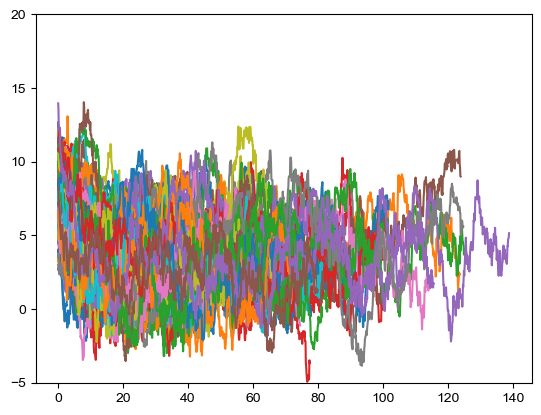

In [57]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], Testtemp_lettuce[i])
plt.ylim([-5.05, 20.05])
plt.show()

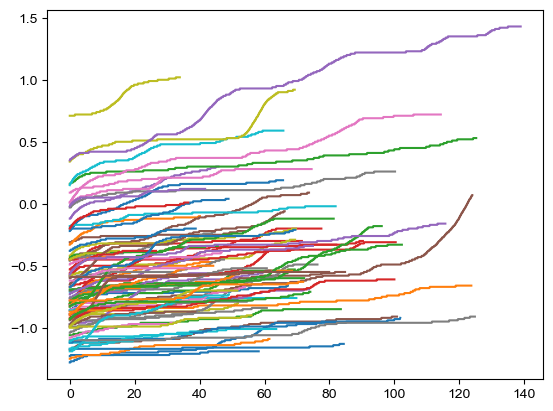

In [58]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], TestlogC_lettuce[i])
plt.show()

In [59]:
np.sum(Sim_results ["checkInf"])

308

(array([3.123e+03, 3.261e+03, 2.747e+03, 1.744e+03, 9.330e+02, 3.310e+02,
        5.300e+01, 5.000e+00, 2.000e+00, 1.000e+00]),
 array([0.69 , 1.137, 1.584, 2.031, 2.478, 2.925, 3.372, 3.819, 4.266,
        4.713, 5.16 ]),
 <BarContainer object of 10 artists>)

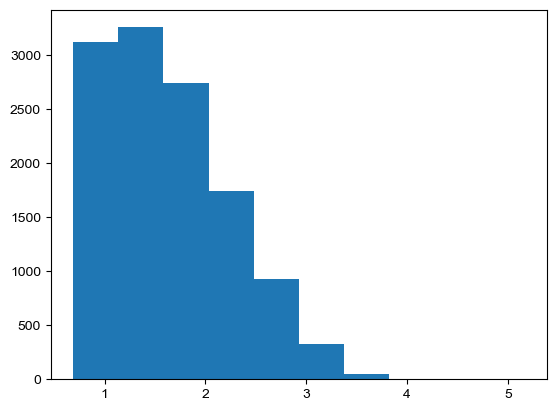

In [60]:
plt.hist(Sim_results ["logC_home_meat"][Sim_results ["logC_home_meat"]!=-np.inf])

(array([38., 40., 61., 58., 37., 32., 16., 16.,  6.,  4.]),
 array([0.   , 0.351, 0.702, 1.053, 1.404, 1.755, 2.106, 2.457, 2.808,
        3.159, 3.51 ]),
 <BarContainer object of 10 artists>)

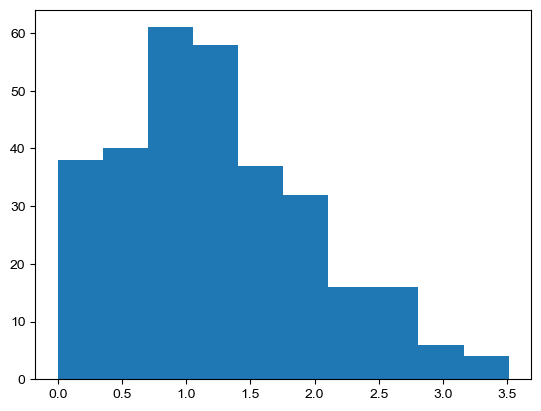

In [61]:
plt.hist(Sim_results["logdose"][Sim_results["checkInf"]==1])

(array([14., 17., 23., 34., 25., 34., 34., 28., 10.,  3.]),
 array([0.83 , 1.106, 1.382, 1.658, 1.934, 2.21 , 2.486, 2.762, 3.038,
        3.314, 3.59 ]),
 <BarContainer object of 10 artists>)

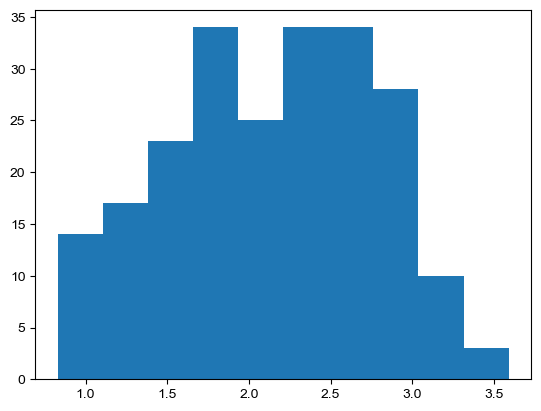

In [62]:
plt.hist(Sim_results["logC_home_meat"][(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-float('inf'))])

In [63]:
#病気の中のレタス有病率
np.sum(Sim_results["checklettuce0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.2792207792207792

In [64]:
#感染の中の肉有病率
np.sum(Sim_results["checkmeat0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.7207792207792207

In [65]:
#感染の中の手洗いしていない率
1-np.sum(Sim_results["checkhandwash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.6266233766233766

(array([ 18., 109., 112.,  83.,  43.,  20.,  16.,   3.,   3.,   2.]),
 array([-1.5  , -1.208, -0.916, -0.624, -0.332, -0.04 ,  0.252,  0.544,
         0.836,  1.128,  1.42 ]),
 <BarContainer object of 10 artists>)

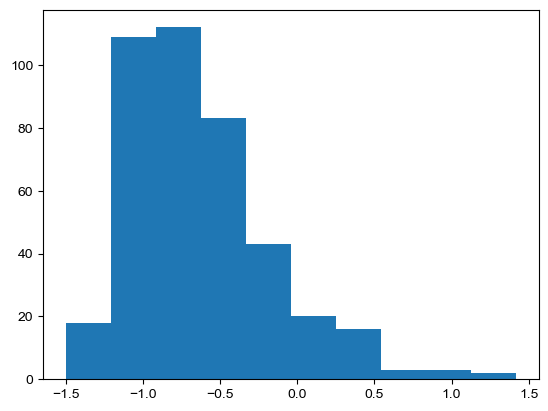

In [66]:
plt.hist(Sim_results ["logC_home_lettuce"][Sim_results ["logC_home_lettuce"]!=-np.inf])

(array([ 9., 19., 19., 19.,  9.,  5.,  2.,  1.,  2.,  1.]),
 array([-1.18, -0.92, -0.66, -0.4 , -0.14,  0.12,  0.38,  0.64,  0.9 ,
         1.16,  1.42]),
 <BarContainer object of 10 artists>)

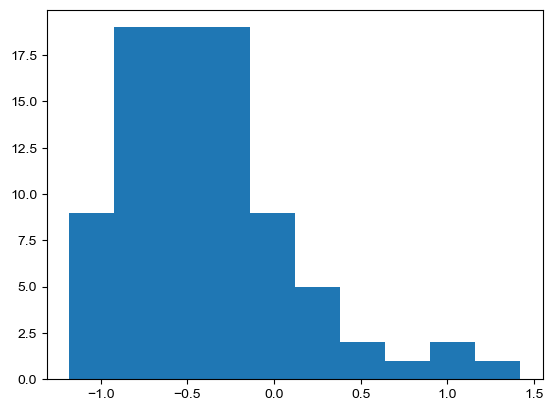

In [67]:
plt.hist(Sim_results ["logC_home_lettuce"][(Sim_results ["checkInf"]!=0)&(Sim_results["logC_home_lettuce"]!=-float('inf'))])

In [68]:
np.sum(Sim_results["checkInf"])

308

In [69]:
np.sum(Sim_results["checklettuce0"])

409

In [70]:
np.sum(Sim_results["checkmeat0"])

12200

In [71]:
np.sum(Sim_results["checkhandwash"])

395840

(0.0, 1.0)

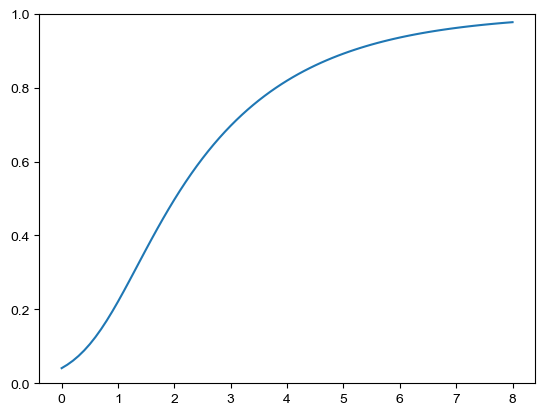

In [72]:
logdds = np.linspace(0, 8, int(8*10+1), endpoint = True)
probss = np.linspace(0, 8, int(8*10+1), endpoint = True)
for i in range (len(logdds)):
    probss[i] = DRmodel_Appro_Beta_Pois(10**logdds[i])
plt.plot(logdds, probss)
plt.ylim([0,1])

In [73]:
np.mean(Sim_results["p_inf"])

0.0005741998485995456

In [1]:
308/528400

0.000582891748675246